# 🏥 Medical Report Extractor – Google Colab GPU Runner

This notebook runs the staged medical extraction pipeline using **Google Colab's free GPU (T4 / A100)**.

### Step 0: Ensure GPU is Enabled
Go to **Runtime** > **Change runtime type** > Select **T4 GPU** (or A100 if Colab Pro) > Click **Save**.

In [ ]:
# Check GPU Availability
!nvidia-smi

### Step 1: Clone Your Repository

In [9]:
!git clone https://github.com/soum-tech/Medical.git
%cd Medical

Cloning into 'Medical'...
remote: Enumerating objects: 60, done.
remote: Counting objects: 100% (60/60), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 60 (delta 17), reused 56 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (60/60), 32.89 KiB | 16.44 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/Medical/Medical


### Step 2: Install Project & GPU Dependencies

In [10]:
# !pip install --upgrade pip
# !pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
# !pip install "transformers>=5.3.0" "accelerate>=1.0.0" pymupdf Pillow pydantic python-dotenv huggingface_hub
!pip install -e .

Obtaining file:///content/Medical/Medical
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for medical-report-extractor (pyproject.toml) ... done
  Created wheel for medical-report-extractor: filename=medical_report_extractor-0.1.0-0.editable-py3-none-any.whl size=5752 sha256=aa3697a54a19424a8aaf3ffc4addf344450f40e7da391cff60d531b5014e06a1
  Stored in directory: /tmp/pip-ephem-wheel-cache-tmu5n5fg/wheels/68/d8/6a/a5ce8a05942d1985105b346c337a5dc8c74ab5fcbf9f7f0446
Successfully built medical-report-extractor
  Attempting uninstall: medical-report-extractor
    Found existing installation: medical-report-extractor 0.1.0
    Uninstalling medical-report-extractor-0.1.0:
      Successfully uninstalled medical-report-extractor-0.1.0


### Step 3: Download Qwen3.5-0.8B Weights Directly to Colab
Colab has high-speed network connections, so downloading takes ~15–30 seconds.

In [12]:
from huggingface_hub import snapshot_download

print("Downloading Qwen3.5-0.8B model weights...")
snapshot_download(
    repo_id="Qwen/Qwen3.5-0.8B",
    local_dir="models/Qwen3.5-0.8B",
)
print("Download complete!")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Download complete!


### Step 4: Configure Local GPU Execution in `.env`

In [13]:
env_content = """BACKEND=local
MODEL_PATH=models/Qwen3.5-0.8B
MODEL_DEVICE_MAP=auto
MODEL_LOCAL_FILES_ONLY=true
MODEL_MAX_NEW_TOKENS=4096
RENDER_DPI=144
MAX_PAGES_PER_CALL=1
MAX_TARGETED_RETRIES=1
"""

with open(".env", "w", encoding="utf-8") as f:
    f.write(env_content)

print(".env configured for Local GPU!")

.env configured for Local GPU!


### Step 5: Upload Your Medical Report (or use a sample in `input/`)
Run this cell if you want to upload a file directly from your computer into Colab.

In [14]:
from google.colab import files
import os

os.makedirs("input", exist_ok=True)
print("Upload your medical PDF or image report:")
uploaded = files.upload()

input_file_path = None
for filename in uploaded.keys():
    destination = os.path.join("input", filename)
    os.replace(filename, destination)
    input_file_path = destination
    print(f"Saved to {destination}")

Upload your medical PDF or image report:


Saving images (1).jpeg to images (1).jpeg
Saved to input/images (1).jpeg


### Step 6: Run Extraction with the Local Model on GPU!

In [20]:
!git pull

remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 6 (delta 4), reused 6 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 1.13 KiB | 387.00 KiB/s, done.
From https://github.com/soum-tech/Medical
   db62bea..ff17a61  main       -> origin/main
Updating db62bea..ff17a61
Fast-forward
 src/medical_report_extractor/dashboard.py | 43 +++++++++++++++++++++----------
 src/medical_report_extractor/pipeline.py  |  9 ++-----
 2 files changed, 31 insertions(+), 21 deletions(-)


In [24]:
import glob

# Auto-detect the uploaded input file, or fallback to the first file in input/
if not input_file_path or not os.path.exists(input_file_path):
    files_in_input = glob.glob("input/*")
    if files_in_input:
        input_file_path = files_in_input[0]
    else:
        raise FileNotFoundError("Please upload a report into input/ before running.")

print(f"Processing report: {input_file_path} on GPU...")
!python -m medical_report_extractor.cli --input "$input_file_path" --output-dir "output"

Processing report: input/images (1).jpeg on GPU...
Loading weights: 100% 473/473 [00:00<00:00, 925.74it/s] 
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attenti

### Step 7: View the Dashboard in Colab & Download Results


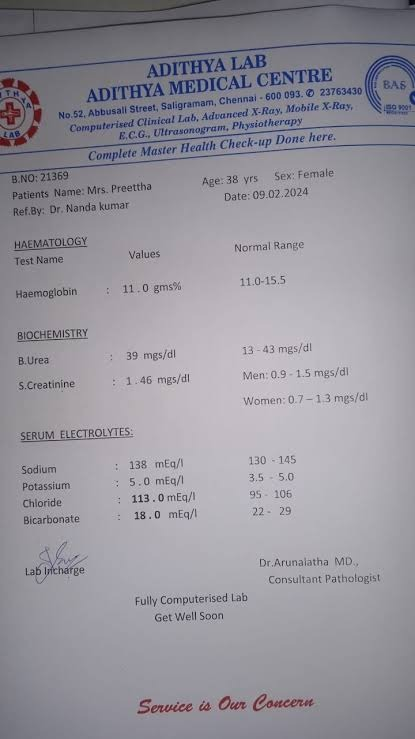

In [25]:
import IPython
from google.colab import files

# 1. Display the interactive review dashboard right inside the Colab notebook
IPython.display.display(IPython.display.HTML(filename="output/dashboard.html"))

In [26]:
# 2. Zip and download output files to your local computer
!zip -r extraction_output.zip output/
files.download("extraction_output.zip")

updating: output/ (stored 0%)
updating: output/medical_report.json (deflated 81%)
updating: output/dashboard.html (deflated 37%)
updating: output/extraction_audit.json (deflated 69%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>